In [16]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score

In [17]:
X_train =np.linspace(-1, 1, 20)
print(X_train)

[-1.         -0.89473684 -0.78947368 -0.68421053 -0.57894737 -0.47368421
 -0.36842105 -0.26315789 -0.15789474 -0.05263158  0.05263158  0.15789474
  0.26315789  0.36842105  0.47368421  0.57894737  0.68421053  0.78947368
  0.89473684  1.        ]


In [18]:
Y_train = np.array([-0.6561 , -0.3099 , -0.59035, -0.50855, -0.285  ,
                    -0.2443 , -0.02445,  0.00135, -0.2006 ,  0.07475,
                    -0.1422 ,  0.06515,  0.15265,  0.3521 ,  0.28415,
                    0.5524 ,  0.23115,  0.20835, 0.4211,  0.60485])

In [19]:
X_test = np.linspace(-1, 1, 20)
print(X_test)

[-1.         -0.89473684 -0.78947368 -0.68421053 -0.57894737 -0.47368421
 -0.36842105 -0.26315789 -0.15789474 -0.05263158  0.05263158  0.15789474
  0.26315789  0.36842105  0.47368421  0.57894737  0.68421053  0.78947368
  0.89473684  1.        ]


In [20]:
Y_test = np.array([-0.69415, -0.451  , -0.43005, -0.4484 , -0.1475 ,
                   -0.5019 , -0.28055,  0.24595, -0.21425, -0.0286 ,
                   0.23415,  0.46575, 0.07955,  0.1973 ,  0.0719 ,
                   0.3639 ,  0.5536 ,  0.3365 , 0.50705,  0.33435])

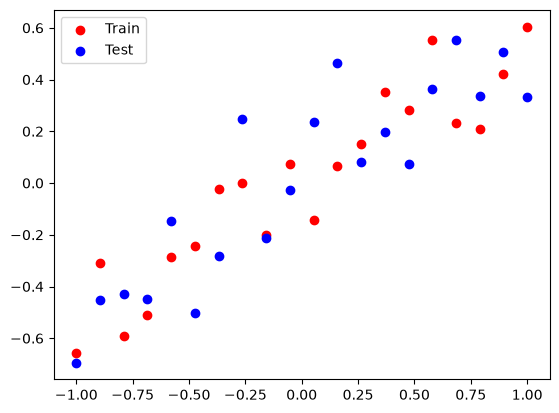

In [21]:
plt.scatter(X_train,Y_train,c="red",label="Train")
plt.scatter(X_test,Y_test,c="blue",label="Test")
plt.legend()
plt.show()

In [22]:
# Resgression Model

model = Sequential()
model.add(Dense(10, activation="relu",input_shape=(1,)))
model.add(Dense(10, activation="relu"))
model.add(Dense(1, activation="linear"))

c:\Users\Prajawal\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [23]:
model.compile(optimizer=Adam(learning_rate=0.01), loss="mean_squared_error",metrics=["mean_squared_error","r2_score"])

In [24]:
history = model.fit(X_train,Y_train,epochs=100,validation_data=(X_test,Y_test))

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 812ms/step - loss: 0.1184 - mean_squared_error: 0.1184 - r2_score: 0.0596 - val_loss: 0.1073 - val_mean_squared_error: 0.1073 - val_r2_score: 0.2257
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 0.0918 - mean_squared_error: 0.0918 - r2_score: 0.2711 - val_loss: 0.0858 - val_mean_squared_error: 0.0858 - val_r2_score: 0.3808
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - loss: 0.0709 - mean_squared_error: 0.0709 - r2_score: 0.4368 - val_loss: 0.0704 - val_mean_squared_error: 0.0704 - val_r2_score: 0.4924
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - loss: 0.0555 - mean_squared_error: 0.0555 - r2_score: 0.5596 - val_loss: 0.0601 - val_mean_squared_error: 0.0601 - val_r2_score: 0.5662
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - loss: 0.0450 - mean_squared_error: 0.0450 - r2_score: 0.6427 - val_loss: 0.0529 - val_mean_squared_error: 0.0529 - val_r2_score: 0.6184
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - loss: 0

In [25]:
# Evaluate the model.

train_mse=model.evaluate(X_train,Y_train,verbose=0)
test_mse=model.evaluate(X_test,Y_test,verbose=0)

print("Train MSE: ",train_mse)
print("Test MSE: ",test_mse)

Train MSE:  [0.014028290286660194, 0.014028290286660194, 0.8886026740074158]
Test MSE:  [0.030780797824263573, 0.030780797824263573, 0.777928352355957]


In [26]:
# Droupout Model

model1 = Sequential()
model1.add(Dense(128, activation="relu",input_shape=(1,)))
model1.add(Dropout(0.3))
model1.add(Dense(128, activation="relu"))
model1.add(Dropout(0.3))
model1.add(Dense(1, activation="linear"))


In [27]:
model1.compile(optimizer=Adam(learning_rate=0.01), loss="mean_squared_error",metrics=["mean_squared_error","r2_score"])

In [28]:
hisstory1 = model1.fit(X_train,Y_train,epochs=100,validation_data=(X_test,Y_test))

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 868ms/step - loss: 0.1163 - mean_squared_error: 0.1163 - r2_score: 0.0762 - val_loss: 0.0464 - val_mean_squared_error: 0.0464 - val_r2_score: 0.6655
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - loss: 0.0234 - mean_squared_error: 0.0234 - r2_score: 0.8142 - val_loss: 0.0524 - val_mean_squared_error: 0.0524 - val_r2_score: 0.6222
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - loss: 0.0428 - mean_squared_error: 0.0428 - r2_score: 0.6603 - val_loss: 0.0362 - val_mean_squared_error: 0.0362 - val_r2_score: 0.7391
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - loss: 0.0201 - mean_squared_error: 0.0201 - r2_score: 0.8404 - val_loss: 0.0374 - val_mean_squared_error: 0.0374 - val_r2_score: 0.7301
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - loss: 0.0345 - mean_squared_error: 0.0345 - r2_score: 0.7257 - val_loss: 0.0376 - val_mean_squared_error: 0.0376 - val_r2_score: 0.7291
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - loss: 0

In [29]:
# Evaluate the model.

train_mse=model1.evaluate(X_train,Y_train,verbose=0)
test_mse=model1.evaluate(X_test,Y_test,verbose=0)

print("Train MSE: ",train_mse)
print("Test MSE: ",test_mse)

Train MSE:  [0.016152795404195786, 0.016152795404195786, 0.871732234954834]
Test MSE:  [0.03273146599531174, 0.03273146599531174, 0.76385498046875]


In [30]:
y_pred = model.predict(X_test)
print(y_pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
[[-0.59571767]
 [-0.53251576]
 [-0.47004575]
 [-0.4075757 ]
 [-0.3124444 ]
 [-0.21620934]
 [-0.11997428]
 [-0.08617388]
 [-0.05721033]
 [-0.02824678]
 [ 0.00109056]
 [ 0.086233  ]
 [ 0.17137542]
 [ 0.25651783]
 [ 0.30284786]
 [ 0.33721414]
 [ 0.3715805 ]
 [ 0.4059469 ]
 [ 0.4403133 ]
 [ 0.47467962]]


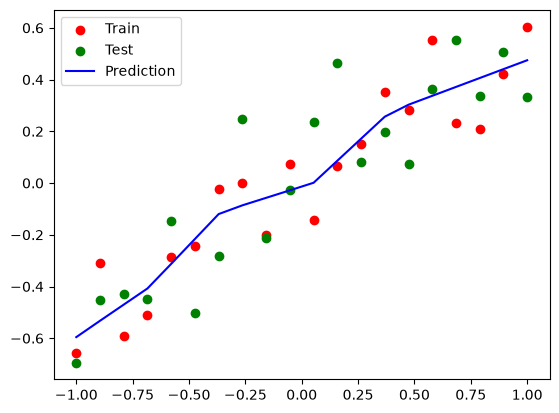

In [32]:
plt.figure()
plt.scatter(X_train,Y_train,c="red",label="Train")
plt.scatter(X_test,Y_test,c="green",label="Test")
plt.plot(X_test,y_pred,c="blue",label="Prediction")
plt.legend()
plt.show()